# Entregable 7 · Grupo 03 · Pronóstico del consumo de la Zona 1 de Tetouan a una hora

**Metodología para Data Science (1ACC0240) · UPC · ciclo 2026-2**

**Cambios respecto de la versión del 4 de noviembre** (la comprensión del negocio, el EDA y la preparación se
mantienen):

1. **Tres referencias ingenuas en vez de una.** Además de la persistencia (el consumo de ahora), se mide "ayer a la
   misma hora" y "la semana pasada a la misma hora". Con la partición de la versión anterior, los dos modelos le
   ganaban a la persistencia pero perdían contra "ayer": el criterio de éxito ahora exige ganarle a **la mejor** de
   las tres.
2. **El objetivo en razón.** Los modelos aprenden el consumo de t+6 dividido por la media de las últimas 24 h, y la
   predicción se multiplica por esa media para volver a kW. Así los árboles pueden predecir niveles que no vieron
   al entrenar (noviembre y diciembre no están en el entrenamiento).
3. **Sin calendario anual** en los modelos (`Year_Sin`, `Year_Cos`): con un solo año, funciona como identificador
   de la época y no generaliza. Entran el consumo de ayer y de la semana pasada a la hora de t+6.
4. **Un hueco de una hora** entre entrenamiento y prueba, para que ningún objetivo del entrenamiento caiga en la
   prueba. **MAPE** junto a RMSE, MAE y R².
5. Diagnóstico (real contra predicho, error por hora, la transferencia de carga del 25 de octubre), importancia de
   variables y conclusiones.

# **Configuración Inicial**

Se instalan y cargan las librerías necesarias para el proyecto:

- `ucimlrepo`: Descarga del dataset directamente desde el repositorio UCI.
- `pandas` y `numpy`: Manipulación y transformación de los datos.
- `matplotlib` y `seaborn`: Visualización.
- `RandomForestRegressor` y `XGBRegressor`: Modelos de Machine Learning
- `mean_squared_error`, `mean_absolute_error` y `r2_score`: Métricas para evaluar los modelos de Machine Learning

In [1]:
pip install ucimlrepo

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import time

# **Comprensión del Negocio**

## **Contexto**
Tetouan es una ciudad del norte de Marruecos cuya red eléctrica se divide en tres zonas de distribución. El operador de distribución debe equilibrar en todo momento la energía que suministra con la que consume la ciudad. Si la demanda supera lo previsto, la red se sobrecarga. Por el contrario, si se sobreestima, se genera o compra energía eléctrica que no se usa, lo que implica costos innecesarios.

## **Problema**
El operador conoce el consumo cuando ya ocurrió. Para planificar la carga necesita saber con anticipación cuánta energía se va a demandar, especialmente en los momentos de mayor consumo.

## **Objetivo del proyecto**
Estimar el consumo eléctrico de la `Zona 1` de Tetouan con 1 hora de anticipación, equivalente a 6 periodos de 10 minutos, a partir de la información disponible en el momento de la predicción.

## **Justificación del horizonte**
Predecir un intervalo hacia el futuro, es decir, 10 minutos adelante, tiene poco valor operativo, ya que el consumo casi no cambia en ese intervalo y el operador no alcanza a reaccionar. Por otro lado, una hora de anticipación permite ajustar la generación o redistribuir carga antes de que ocurra un pico.

## **Criterio de éxito**
El modelo será útil si su error (MAE) es menor que el de **la mejor de tres referencias simples**: que el consumo
dentro de una hora sea igual al actual (persistencia), al de ayer a esa misma hora o al de la semana pasada a esa
misma hora. Cualquiera de las tres se calcula sin modelo; si el modelo no le gana a la mejor, no aporta valor al
negocio.

# **Comprensión de los Datos**

## **Datos del Dataset**

- **Nombre**: Power Consumption of Tetouan City
- **Fuente**: Repositorio UCI Machine Learning (ID 849)
- **Registros**: Contiene registros cada 10 minutos durante el año 2017.

## **Variables del Dataset**

| Variable | Tipo | Descripción |
|---|---|---|
| DateTime | Fecha | Momento del registro (cada 10 minutos) |
| Temperature | Continua | Temperatura de la ciudad (°C) |
| Humidity | Continua | Humedad relativa (%) |
| Wind Speed | Continua | Velocidad del viento |
| general diffuse flows | Continua | Radiación solar difusa general |
| diffuse flows | Continua | Radiación solar difusa |
| Zone 1 Power Consumption | Continua | Consumo eléctrico de la Zona 1 (kW) |
| Zone 2 Power Consumption | Continua | Consumo eléctrico de la Zona 2 (kW) |
| Zone 3 Power Consumption | Continua | Consumo eléctrico de la Zona 3 (kW) |

## **Previsualización de los Datos**

In [3]:
power_consumption_of_tetouan_city = fetch_ucirepo(id=849)

X_raw = power_consumption_of_tetouan_city.data.features
y_raw = power_consumption_of_tetouan_city.data.targets

print("Resumen del dataset")
print(f"Cantidad de registros: {X_raw.shape[0]}")
print(f"Cantidad de variables predictoras: {X_raw.shape[1]}")
print(f"Cantidad de variables objetivo: {y_raw.shape[1]}")

df = X_raw.join(y_raw)

print()
df.info()

print()
print(power_consumption_of_tetouan_city.variables)

print("\n--- Resumen Estadístico ---")
display(df.describe().T)

display(df.head())

Resumen del dataset
Cantidad de registros: 52416
Cantidad de variables predictoras: 6
Cantidad de variables objetivo: 3

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   DateTime                   52416 non-null  object 
 1   Temperature                52416 non-null  float64
 2   Humidity                   52416 non-null  float64
 3   Wind Speed                 52416 non-null  float64
 4   general diffuse flows      52416 non-null  float64
 5   diffuse flows              52416 non-null  float64
 6   Zone 1 Power Consumption   52416 non-null  float64
 7   Zone 2  Power Consumption  52416 non-null  float64
 8   Zone 3  Power Consumption  52416 non-null  float64
dtypes: float64(8), object(1)
memory usage: 3.6+ MB

                        name     role        type demographic  \
0                   DateTime  Feature

,count,mean,std,min,25%,50%,75%,max
Temperature,52416.0,18.810024,5.815476,3.247000,14.410000,18.780000,22.890000,40.01000
Humidity,52416.0,68.259518,15.551177,11.340000,58.310000,69.860000,81.400000,94.80000
Wind Speed,52416.0,1.959489,2.348862,0.050000,0.078000,0.086000,4.915000,6.48300
general diffuse flows,52416.0,182.696614,264.400960,0.004000,0.062000,5.035500,319.600000,1163.00000
diffuse flows,52416.0,75.028022,124.210949,0.011000,0.122000,4.456000,101.000000,936.00000
Zone 1 Power Consumption,52416.0,32344.970564,7130.562564,13895.696200,26310.668692,32265.920340,37309.018185,52204.39512
Zone 2 Power Consumption,52416.0,21042.509082,5201.465892,8560.081466,16980.766032,20823.168405,24713.717520,37408.86076
Zone 3 Power Consumption,52416.0,17835.406218,6622.165099,5935.174070,13129.326630,16415.117470,21624.100420,47598.32636


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


## **Limpieza preliminar de los datos**

### Limpieza de nombres de columnas
Las columnas `Zone 2  Power Consumption` y `Zone 3  Power Consumption` tienen un espacio de más, así que las vamos a transformar para evitar posibles errores de digitación en el futuro

In [4]:
df.columns = df.columns.str.strip().str.replace(r"\s+", " ", regex=True)

### Limpieza de la variable Datetime
La variable `Datetime` es reconocida por Python como tipo `object`. Para un análisis más consistente, se transforma la variable a tipo `datetime64`. También se comprueba si alguna fecha no fue posible convertirla

In [5]:
df["DateTime"] = pd.to_datetime(df["DateTime"], format="%m/%d/%Y %H:%M")
df = df.sort_values("DateTime").reset_index(drop=True)
print(df["DateTime"].head())
print(f"Fechas no convertidas (NaT): {df['DateTime'].isnull().sum()}")

0   2017-01-01 00:00:00
1   2017-01-01 00:10:00
2   2017-01-01 00:20:00
3   2017-01-01 00:30:00
4   2017-01-01 00:40:00
Name: DateTime, dtype: datetime64[ns]
Fechas no convertidas (NaT): 0


## **Revisión de los datos**

### Intervalo de los registros
Como se mencionó anteriormente, deberían estar los registros divididos exactamente entre un intervalo de 10 minutos cada uno

In [6]:
df = df.sort_values("DateTime").reset_index(drop=True)

print(f"Fecha inicial: {df['DateTime'].min()}")
print(f"Fecha final: {df['DateTime'].max()}")
print(f"Días cubiertos: {df['DateTime'].dt.date.nunique()}")
print(f"Fechas duplicadas: {df['DateTime'].duplicated().sum()}")

intervalos = df["DateTime"].diff().dropna()
print("\n--- Intervalos entre registros ---")
print(intervalos.value_counts())

huecos = df[df["DateTime"].diff() > pd.Timedelta(minutes=10)]
print(f"\nHuecos en la serie: {len(huecos)}")

Fecha inicial: 2017-01-01 00:00:00
Fecha final: 2017-12-30 23:50:00
Días cubiertos: 364
Fechas duplicadas: 0

--- Intervalos entre registros ---
DateTime
0 days 00:10:00    52415
Name: count, dtype: int64

Huecos en la serie: 0


### Valores faltantes

In [7]:
print("--- Valores faltantes por columna ---")
print(df.isnull().sum())

print(f"\nTotal de valores faltantes: {df.isnull().sum().sum()}")
print(f"Porcentaje de valores faltantes: {df.isnull().mean().mean() * 100:.2f}%")

--- Valores faltantes por columna ---
DateTime                    0
Temperature                 0
Humidity                    0
Wind Speed                  0
general diffuse flows       0
diffuse flows               0
Zone 1 Power Consumption    0
Zone 2 Power Consumption    0
Zone 3 Power Consumption    0
dtype: int64

Total de valores faltantes: 0
Porcentaje de valores faltantes: 0.00%


## **Valores Atípicos (Outliers)**

Se utiliza el criterio del rango intercuartílico para encontrar outliers. Un valor `v` es atípico si:
- $v < Q1 - 1.5·IQR$
- $v > Q3 + 1.5·IQR$

### Variables Climáticas

In [8]:
climate_columns = ["Temperature", "Humidity", "Wind Speed", "general diffuse flows", "diffuse flows"]

summary = []
for col in climate_columns:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    summary.append({
        "Variable": col,
        "Mínimo": df[col].min(),
        "Límite inferior": lim_inf,
        "Q1": q1,
        "Mediana": df[col].median(),
        "Media": df[col].mean(),
        "Q3": q3,
        "Límite superior": lim_sup,
        "Máximo": df[col].max(),
        "Outliers": outliers,
        "% del total": round(100 * outliers / len(df), 1),
        "Asimetría": round(df[col].skew(), 3),
    })

display(pd.DataFrame(summary))

,Variable,Mínimo,Límite inferior,Q1,Mediana,Media,Q3,Límite superior,Máximo,Outliers,% del total,Asimetría
0,Temperature,3.247,1.6900,14.410,18.7800,18.810024,22.890,35.6100,40.010,142,0.3,0.197
1,Humidity,11.340,23.6750,58.310,69.8600,68.259518,81.400,116.0350,94.800,291,0.6,-0.625
2,Wind Speed,0.050,-7.1775,0.078,0.0860,1.959489,4.915,12.1705,6.483,0,0.0,0.462
3,general diffuse flows,0.004,-479.2450,0.062,5.0355,182.696614,319.600,798.9070,1163.000,2315,4.4,1.307
4,diffuse flows,0.011,-151.1950,0.122,4.4560,75.028022,101.000,252.3170,936.000,4571,8.7,2.457


- `general diffuse flows y diffuse flows`: la radiación vale casi 0 toda la noche y sube mucho al mediodía, por lo que su distribución es sesgada y sigue el ciclo día/noche.
- `Temperature` y `Humidity`: son pocos casos y están dentro de rangos posibles para Tetouan.

### Variables Zone [1,2,3] Power Consumption

In [9]:
summary = []

for i in range(1,4):
  col = f"Zone {i} Power Consumption"
  q1, q3 = df[col].quantile([0.25, 0.75])
  iqr = q3 - q1
  lim_inf = q1 - 1.5 * iqr
  lim_sup = q3 + 1.5 * iqr
  outliers = df[(df[col] < lim_inf) | (df[col] > lim_sup)]
  summary.append({
      "Variable": col,
      "Mínimo": round(df[col].min(), 2),
      "Límite inferior": round(lim_inf, 2),
      "Q1": round(q1, 2),
      "Mediana": round(df[col].median(), 2),
      "Media": round(df[col].mean(), 2),
      "Q3": round(q3, 2),
      "Límite superior": round(lim_sup, 2),
      "Máximo": round(df[col].max(), 2),
      "Outliers": len(outliers),
      "% del total": f"{round(100 * len(outliers) / len(df), 1)}%",
      "V <= 0": (df[col] <= 0).sum(),
      "Asimetría": round(df[col].skew(), 3)
  })
display(pd.DataFrame(summary))

,Variable,Mínimo,Límite inferior,Q1,Mediana,Media,Q3,Límite superior,Máximo,Outliers,% del total,V <= 0,Asimetría
0,Zone 1 Power Consumption,13895.70,9813.14,26310.67,32265.92,32344.97,37309.02,53806.54,52204.40,0,0.0%,0,0.229
1,Zone 2 Power Consumption,8560.08,5381.34,16980.77,20823.17,21042.51,24713.72,36313.14,37408.86,7,0.0%,0,0.329
2,Zone 3 Power Consumption,5935.17,387.17,13129.33,16415.12,17835.41,21624.10,34366.26,47598.33,1191,2.3%,0,1.024


`Zone 1 Power Consumption` tiene una media y una mediana muy cercanas, lo que indica una distribución casi simétrica, y no presenta valores fuera del IQR ni valores en cero o negativos. Sus datos no requieren tratamiento.

`Zone 2 Power Consumption` presenta muy pocos valores fuera del IQR (menos del 0.1% del total) y un leve sesgo a la derecha. Al ser tan pocos y estar dentro de un rango plausible de consumo, se consideran picos reales de demanda.

`Zone 3 Power Consumption` es la zona con más valores atípicos y el sesgo a la derecha más marcado: la media supera claramente a la mediana. Los valores por encima del límite superior del IQR se concentran en los meses de verano, los de más calor. Por lo tanto, corresponden a demanda real de temporada y no a errores de medición.

Ahora se revisará la distribución temporal de los outliers de Zone [1,2,3] Power Consumption

In [10]:
for i in range(1, 4):
    col = f"Zone {i} Power Consumption"

    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr

    outliers = df[
        (df[col] < lim_inf) | (df[col] > lim_sup)
    ]

    if outliers.empty:
        continue

    print("========================")
    print(f"{col}")
    print("========================")
    print(f"\nTotal de valores atípicos: {len(outliers)}")

    print("\nDistribución por mes:")
    print(outliers["DateTime"].dt.month.value_counts().sort_index())

    print("\nDistribución por hora:")
    print(outliers["DateTime"].dt.hour.value_counts().sort_index())
    print("\n")

Zone 2 Power Consumption

Total de valores atípicos: 7

Distribución por mes:
DateTime
7    2
8    5
Name: count, dtype: int64

Distribución por hora:
DateTime
19    3
20    4
Name: count, dtype: int64


Zone 3 Power Consumption

Total de valores atípicos: 1191

Distribución por mes:
DateTime
7    760
8    431
Name: count, dtype: int64

Distribución por hora:
DateTime
0      17
12      3
13      5
18      9
19    222
20    317
21    299
22    217
23    102
Name: count, dtype: int64




## **Comportamiento temporal de los picos de consumo**

Además de la media, la mediana y el IQR, se analiza cuándo ocurren los picos de cada zona.

Se realiza un análisis a lo largo del año, por hora del día, por día de la semana y por mes.

Se grafica el pico y, como referencia, el promedio.

### Configuración Inicial para los gráficos

Colores para los gráficos:
- <font color="royalblue">Zone 1</font>
- <font color="darkorange">Zone 2</font>
- <font color="seagreen">Zone 3</font>



In [11]:
df_eda = df.copy()
df_eda["Hora"] = df_eda["DateTime"].dt.hour
df_eda["Mes"] = df_eda["DateTime"].dt.month
df_eda["DiaSemana"] = df_eda["DateTime"].dt.dayofweek

ZONES = [
    "Zone 1 Power Consumption",
    "Zone 2 Power Consumption",
    "Zone 3 Power Consumption"
]

zone_labels = ["Zona 1", "Zona 2", "Zona 3"]
colors = ["royalblue", "darkorange", "seagreen"]

### Evolución de Picos Diarios

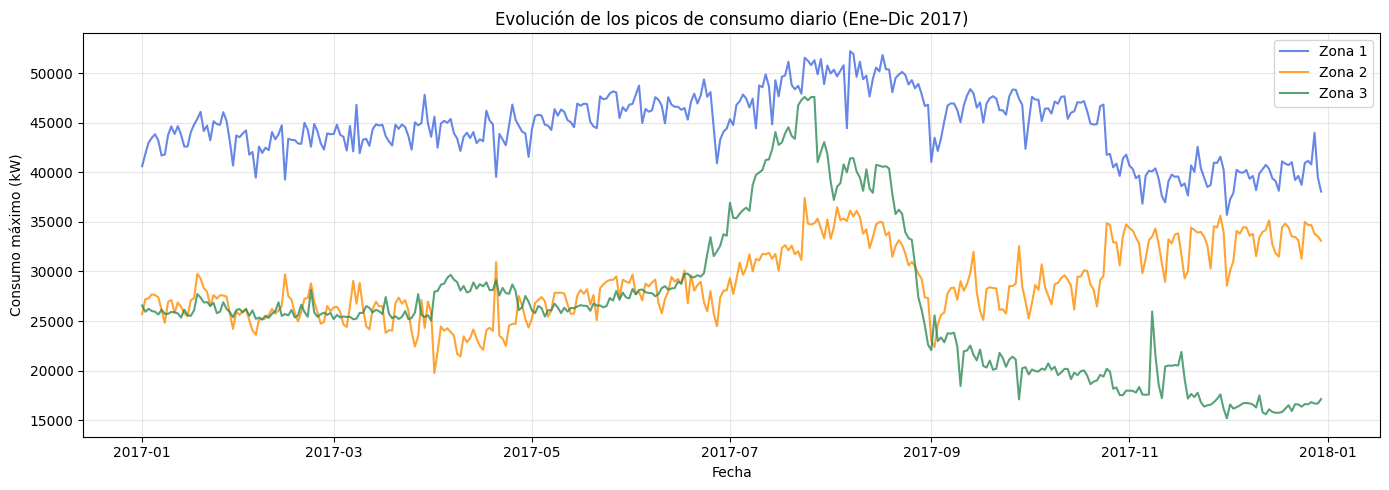

In [12]:
picos_diarios = df_eda.groupby(df_eda["DateTime"].dt.date)[ZONES].max()
plt.figure(figsize=(14, 5))
for col, label, color in zip(ZONES, zone_labels, colors):
    plt.plot(
        picos_diarios.index,
        picos_diarios[col],
        label=label,
        color=color,
        alpha=0.8
    )

plt.title("Evolución de los picos de consumo diario (Ene–Dic 2017)")
plt.xlabel("Fecha")
plt.ylabel("Consumo máximo (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Consumo por Hora

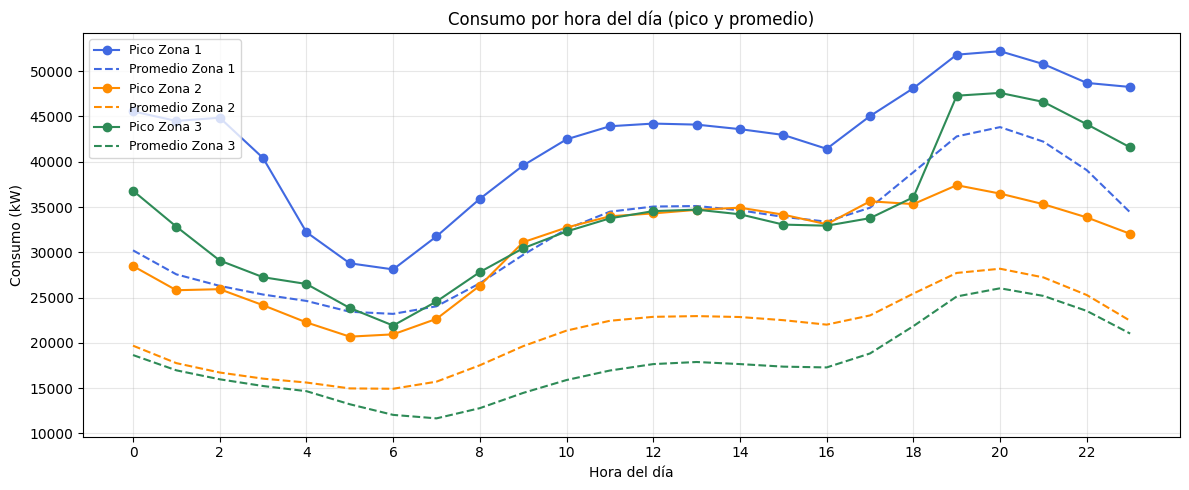

Hora de mayor consumo promedio por zona:
Zone 1 Power Consumption    20
Zone 2 Power Consumption    20
Zone 3 Power Consumption    20
dtype: int32


In [13]:
picos_horarios = df_eda.groupby("Hora")[ZONES].max()
prom_horarios = df_eda.groupby("Hora")[ZONES].mean()

plt.figure(figsize=(12, 5))

for col, label, color in zip(ZONES, zone_labels, colors):
    plt.plot(
        picos_horarios.index,
        picos_horarios[col],
        label=f"Pico {label}",
        color=color,
        marker="o"
    )
    plt.plot(
        prom_horarios.index,
        prom_horarios[col],
        label=f"Promedio {label}",
        color=color,
        linestyle="--"
    )

plt.title("Consumo por hora del día (pico y promedio)")
plt.xlabel("Hora del día")
plt.ylabel("Consumo (kW)")
plt.xticks(range(0, 24, 2))
plt.legend(fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Hora de mayor consumo promedio por zona:")
print(prom_horarios.idxmax())

El consumo de las tres zonas es mínimo entre las 4:00 y 6:00 y alcanza su máximo entre las 17:00 y 20:00, alrededor de la hora indicada en la salida anterior.

### Picos por Día de Semana

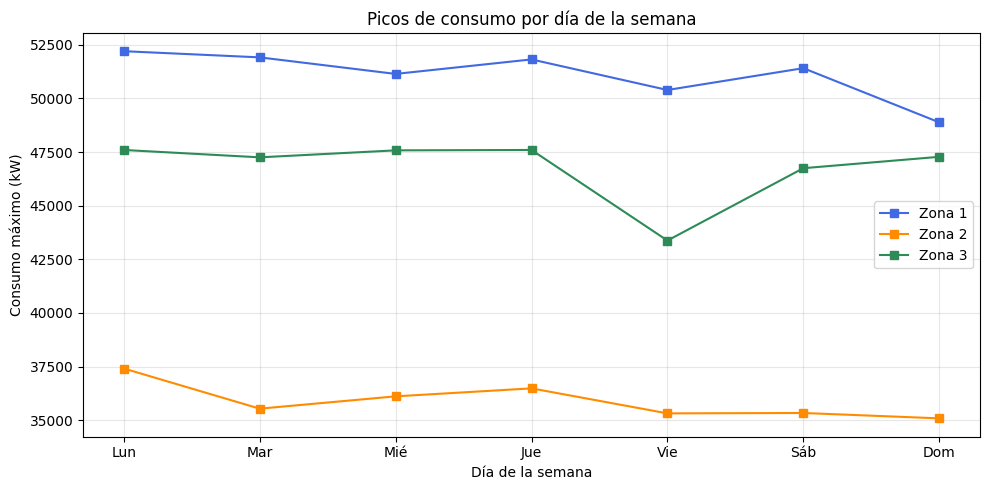

In [14]:
dias_labels = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
picos_semanales = df_eda.groupby("DiaSemana")[ZONES].max()

plt.figure(figsize=(10, 5))
for col, label, color in zip(ZONES, zone_labels, colors):
    plt.plot(
        dias_labels,
        picos_semanales[col],
        label=label,
        color=color,
        marker="s"
    )

plt.title("Picos de consumo por día de la semana")
plt.xlabel("Día de la semana")
plt.ylabel("Consumo máximo (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

En las zonas 1 y 2 el pico más bajo es el del domingo; en la zona 3, el del viernes, unos 9 % por debajo del resto
de la semana. Las zonas 1 y 2 tienen picos parecidos de lunes a sábado, mientras que la zona 3 baja claramente los
viernes.

### Variación Estacional de los Picos

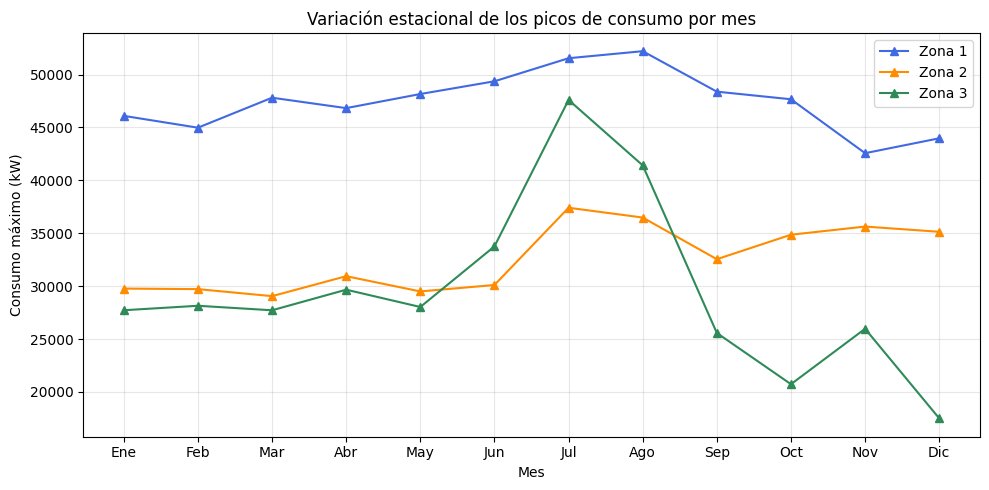

In [15]:
meses_labels = [
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"
]

picos_mensuales = df_eda.groupby("Mes")[ZONES].max()

plt.figure(figsize=(10, 5))
for col, label, color in zip(ZONES, zone_labels, colors):
    plt.plot(
        meses_labels,
        picos_mensuales[col],
        label=label,
        color=color,
        marker="^"
    )

plt.title("Variación estacional de los picos de consumo por mes")
plt.xlabel("Mes")
plt.ylabel("Consumo máximo (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

La Zona 3 presenta picos muy por encima del resto del año en julio y agosto, que explican sus valores atípicos. Zone 1 y Zone 2 muestran un consumo constante en el año, aunque también hay un alza en los meses de verano, pero no tanto como la zona 3.

# **Preparación de los Datos**

## **Tratamiento de Outliers**

### Análisis

- `Zone 3 Power Consumption`: los registros por encima del límite superior del IQR se concentran en julio y agosto, los meses de más calor. Corresponden a demanda real de verano, no a errores de medición.
- `general diffuse flows` y `diffuse flows`: la radiación vale casi 0 toda la noche y sube mucho al mediodía; su distribución sesgada sigue el ciclo día/noche.
- `Temperature` y `Humidity`: son pocos casos y están dentro de rangos posibles para Tetouan.
- `Zone 1 Power Consumption` no tiene outliers y `Zone 2 Power Consumption` solo unos pocos.

### Decisión

No se elimina ni se recorta ningún valor. Todos son mediciones razonables, y quitar los picos haría que el modelo subestime justo los periodos de mayor demanda, que son los que el negocio necesita anticipar.

## **Creación de Variables**

### Variables de calendario y codificación cíclica

In [16]:
df["MinuteOfDay"] = df["DateTime"].dt.hour * 60 + df["DateTime"].dt.minute
df["DayOfWeek"] = df["DateTime"].dt.dayofweek
df["DayOfYear"] = df["DateTime"].dt.dayofyear
df["IsWeekend"] = (df["DayOfWeek"] >= 5).astype(int)

df["Time_Sin"] = np.sin(2 * np.pi * df["MinuteOfDay"] / 1440)
df["Time_Cos"] = np.cos(2 * np.pi * df["MinuteOfDay"] / 1440)
df["Week_Sin"] = np.sin(2 * np.pi * df["DayOfWeek"] / 7)
df["Week_Cos"] = np.cos(2 * np.pi * df["DayOfWeek"] / 7)
df["Year_Sin"] = np.sin(2 * np.pi * (df["DayOfYear"] - 1) / 365)
df["Year_Cos"] = np.cos(2 * np.pi * (df["DayOfYear"] - 1) / 365)

### Lags y estadísticas móviles

In [17]:
lags = [0, 1, 2, 6]
for lag in lags:
    suffix = "_t" if lag == 0 else f"_t_minus_{lag}"
    df[f"Zone1{suffix}"] = df["Zone 1 Power Consumption"].shift(lag)
    df[f"Zone2{suffix}"] = df["Zone 2 Power Consumption"].shift(lag)
    df[f"Zone3{suffix}"] = df["Zone 3 Power Consumption"].shift(lag)

### Consumo de ayer, de la semana pasada y media de 24 horas

El consumo a la hora que se quiere predecir se repite de un día a otro y de una semana a otra, así que se agregan
el consumo de ayer y el de la semana pasada **a la hora de t+6** (ya se conocen en t). La media de las últimas 24 h
de cada zona es la escala con la que se lleva todo a razón en el modelado.

In [18]:
H = 6          # horizonte: 6 periodos de 10 minutos = 1 hora
DIA = 144      # periodos de 10 minutos en un día
SEMANA = 1008  # periodos de 10 minutos en una semana

z1 = df["Zone 1 Power Consumption"]
df["Zone1_ayer"] = z1.shift(DIA - H)               # ayer, a la hora de t+6
df["Zone1_semana_pasada"] = z1.shift(SEMANA - H)   # la semana pasada, a la hora de t+6
for i in range(1, 4):
    df[f"Zone{i}_media_24h"] = df[f"Zone {i} Power Consumption"].rolling(DIA).mean()

### Variable Target

Se predice el consumo de la Zona 1 una hora adelante. Al quitar los nulos de los rezagos se pierde la primera semana
del año, que hace falta para el consumo de la semana pasada.

In [19]:
df["Zone1_Rolling_Mean_1h"] = df["Zone 1 Power Consumption"].rolling(window=6).mean()
df["Zone1_Rolling_Std_1h"] = df["Zone 1 Power Consumption"].rolling(window=6).std()

# Variable target (1 hora hacia adelante, equivalente a 6 periodos de 10 min)
df["Target_Zone1_t_plus_6"] = df["Zone 1 Power Consumption"].shift(-6)

# Limpieza de nulos por los shifts
df_model = df.dropna().reset_index(drop=True)
df_model.head()

,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption,MinuteOfDay,...,Zone2_t_minus_6,Zone3_t_minus_6,Zone1_ayer,Zone1_semana_pasada,Zone1_media_24h,Zone2_media_24h,Zone3_media_24h,Zone1_Rolling_Mean_1h,Zone1_Rolling_Std_1h,Target_Zone1_t_plus_6
0,2017-01-07 23:00:00,13.08,78.9,0.078,0.055,0.130,33812.65823,21125.83587,22074.21687,1380,...,23923.40426,24375.90361,28927.59494,34055.69620,30619.071730,19270.997973,17957.309237,35402.531645,1211.701321,28332.15190
1,2017-01-07 23:10:00,13.24,78.9,0.078,0.051,0.148,32955.94937,20844.98480,21727.22892,1390,...,23675.37994,23826.50602,28052.65823,29814.68354,30618.818565,19265.045592,17963.453815,34715.949367,1240.956196,27791.39241
2,2017-01-07 23:20:00,13.44,79.0,0.084,0.070,0.134,31868.35443,20316.10942,21339.75904,1400,...,23058.96657,23635.66265,27220.25316,29128.10127,30617.890295,19260.891590,17969.317269,33966.582278,1394.377648,26831.39241
3,2017-01-07 23:30:00,13.70,78.5,0.084,0.048,0.145,30914.43038,19809.11854,20686.26506,1410,...,22723.40426,23433.25301,26831.39241,28228.86076,30616.033755,19256.636271,17973.815261,33173.670887,1572.050972,26296.70886
4,2017-01-07 23:40:00,13.83,77.9,0.084,0.048,0.156,30203.54430,19546.50456,20298.79518,1420,...,22096.04863,22883.85542,26363.54430,27335.69620,30615.189873,19255.015197,17980.240964,32370.632912,1666.953810,25585.82278


# **Modelado**

## **Selección de Modelos**

Para el problema de regresión sobre series de tiempo con dependencias no lineales y dinámicas climáticas, se han seleccionado los siguientes modelos:

### <font color="royalblue">Random Forest Regressor</font>

Es un algoritmo robusto que permite manejar eficientemente datos tabulares con relaciones no lineales complejas sin requerir de un preprocesamiento extremo a escala.

Al promediar múltiples árboles de decisión, es menos propenso a overfitting y captura de manera efectiva los picos y consumos diarios y estacionales.

### <font color="royalblue">XGBoost Regressor</font>

Es un algoritmo que optimiza una función de pérdida de forma secuencial mediante el descenso de gradiente.

Es eficiente para el modelado de datos tabulares con buen manejo de memoria y se adapta con gran precisión a los patrones temporales, reduciendo así el sesgo de predicción.

## **Plantamiento de evaluación**

### Definición

### Definición

Se evaluarán los modelos con una división cronológica de los datos: los datos más antiguos para entrenar y los más
recientes para probar, 80/20. Entre los dos tramos se deja **un hueco de una hora** (6 periodos): sin él, los
objetivos de las últimas filas del entrenamiento caerían dentro de la prueba.

### Métricas

### Métricas

- `MAE`: la magnitud promedio del error en unidades reales (kW). Es la métrica del criterio de éxito.
- `RMSE`: castiga más los errores grandes, como fallar en un pico de demanda.
- `MAPE`: el error promedio en porcentaje, fácil de comunicar.
- `R²`: la variabilidad explicada. Con una serie tan regular, hasta la persistencia tiene un R² alto, así que no
  sirve sola para decidir.

Cada modelo se compara con las tres referencias simples (persistencia, ayer y semana pasada) y, sobre todo, con la
mejor de ellas en la prueba.

## **Entrenamiento**

### Definición de Features y Variable Target

Se entrenan dos versiones de cada modelo:

- **En nivel (versión del parcial):** predicen el consumo en kW con las variables de la versión anterior, incluido
  el calendario anual. Se mantienen para mostrar qué cambia.
- **En razón:** predicen `consumo(t+6) / media_24h(t)`. El consumo de las tres zonas (actual, rezagos, ayer y semana
  pasada) entra dividido por la media de 24 h de su zona, junto con el clima en t y el calendario diario y
  semanal. La predicción se multiplica por la media de 24 h para volver a kW.

La variable que se quiere predecir es `Target_Zone1_t_plus_6`.

In [20]:
# Versión del parcial: el consumo en nivel, con el calendario anual
features_nivel = [
    'Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows',
    'Time_Sin', 'Time_Cos', 'Week_Sin', 'Week_Cos', 'Year_Sin', 'Year_Cos',
    'Zone1_t', 'Zone2_t', 'Zone3_t',
    'Zone1_t_minus_1', 'Zone2_t_minus_1', 'Zone3_t_minus_1',
    'Zone1_t_minus_2', 'Zone2_t_minus_2', 'Zone3_t_minus_2',
    'Zone1_t_minus_6', 'Zone2_t_minus_6', 'Zone3_t_minus_6',
    'Zone1_Rolling_Mean_1h', 'Zone1_Rolling_Std_1h'
]
target = 'Target_Zone1_t_plus_6'


def en_razon(datos):
    # Variables en razón: el consumo de cada zona dividido por su media de 24 h; el clima y el calendario, igual
    r = datos[['Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows',
               'Time_Sin', 'Time_Cos', 'Week_Sin', 'Week_Cos', 'IsWeekend']].copy()
    for i in range(1, 4):
        escala = datos[f"Zone{i}_media_24h"]
        for sufijo in ["_t", "_t_minus_1", "_t_minus_2", "_t_minus_6"]:
            r[f"Zone{i}{sufijo}"] = datos[f"Zone{i}{sufijo}"] / escala
    escala1 = datos["Zone1_media_24h"]
    for col in ["Zone1_ayer", "Zone1_semana_pasada", "Zone1_Rolling_Mean_1h", "Zone1_Rolling_Std_1h"]:
        r[col] = datos[col] / escala1
    return r


X_nivel = df_model[features_nivel]
X_razon = en_razon(df_model)
escala = df_model["Zone1_media_24h"]
y = df_model[target]
y_razon = y / escala
print(f"Variables en nivel: {X_nivel.shape[1]} · variables en razón: {X_razon.shape[1]}")

Variables en nivel: 25 · variables en razón: 26


### División Cronológica y Referencias Simples
Se mantiene el 80% entrenamiento / 20% prueba, con el hueco de una hora entre los dos.

Las tres referencias simples predicen que el consumo en t+6 será igual al de ahora (persistencia), al de ayer a esa
hora o al de la semana pasada a esa hora.

In [21]:
split_idx = int(len(df_model) * 0.8)
tr = slice(0, split_idx - H)        # el hueco: las últimas 6 filas tienen su objetivo dentro de la prueba
te = slice(split_idx, len(df_model))

y_train, y_test = y.iloc[tr], y.iloc[te]
fechas_test = df_model["DateTime"].iloc[te]
print(f"Entrenamiento: {df_model['DateTime'].iloc[tr].min()} a {df_model['DateTime'].iloc[tr].max()} · {len(y_train)} filas")
print(f"Prueba:        {fechas_test.min()} a {fechas_test.max()} · {len(y_test)} filas")

referencias = {
    "Persistencia": df_model["Zone1_t"].iloc[te],
    "Ayer": df_model["Zone1_ayer"].iloc[te],
    "Semana pasada": df_model["Zone1_semana_pasada"].iloc[te],
}

Entrenamiento: 2017-01-07 23:00:00 a 2017-10-20 12:10:00 · 41120 filas
Prueba:        2017-10-20 13:20:00 a 2017-12-30 22:50:00 · 10282 filas


### Entrenamiento de los Modelos

Los mismos hiperparámetros de la versión anterior en las dos versiones, para que la comparación sea justa.
XGBoost entrena en la GPU cuando la hay (`device="cuda"`); si no, en la CPU.

In [22]:
import shutil
import warnings

DISPOSITIVO = "cuda" if shutil.which("nvidia-smi") else "cpu"
print("XGBoost entrena en:", DISPOSITIVO)
warnings.filterwarnings("ignore", message=".*mismatched devices.*")  # predecir con datos de pandas desde la GPU


def random_forest():
    return RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)


def xgboost():
    return XGBRegressor(n_estimators=150, learning_rate=0.08, max_depth=6, random_state=42, n_jobs=-1,
                        device=DISPOSITIVO)


modelos = {}
predicciones = {}
for nombre, crear in [("Random Forest", random_forest), ("XGBoost", xgboost)]:
    inicio = time.time()
    m = crear().fit(X_nivel.iloc[tr], y_train)
    modelos[f"{nombre} (nivel)"] = m
    predicciones[f"{nombre} (nivel)"] = m.predict(X_nivel.iloc[te])
    m = crear().fit(X_razon.iloc[tr], y_razon.iloc[tr])
    modelos[f"{nombre} (razón)"] = m
    predicciones[f"{nombre} (razón)"] = escala.iloc[te].to_numpy() * m.predict(X_razon.iloc[te])
    print(f"{nombre}: {time.time() - inicio:.1f} s")

XGBoost entrena en: cuda


Random Forest: 37.4 s


XGBoost: 0.9 s


## Evaluación de Desempeño

In [23]:
def metricas(real, pred):
    real, pred = np.asarray(real, dtype=float), np.asarray(pred, dtype=float)
    return {"MAE (kW)": mean_absolute_error(real, pred),
            "RMSE (kW)": np.sqrt(mean_squared_error(real, pred)),
            "MAPE (%)": 100 * np.mean(np.abs((real - pred) / real)),
            "R2": r2_score(real, pred)}


df_results = pd.DataFrame({nombre: metricas(y_test, p) for nombre, p in {**referencias, **predicciones}.items()}).T
mejor_ref = df_results.loc[list(referencias), "MAE (kW)"].idxmin()
mae_mejor = df_results.loc[mejor_ref, "MAE (kW)"]
df_results["Mejora vs. mejor referencia (%)"] = 100 * (1 - df_results["MAE (kW)"] / mae_mejor)
print("=== COMPARATIVA EN LA PRUEBA ===")
print("Mejor referencia simple:", mejor_ref)
display(df_results.round(2))

=== COMPARATIVA EN LA PRUEBA ===
Mejor referencia simple: Ayer


,MAE (kW),RMSE (kW),MAPE (%),R2,Mejora vs. mejor referencia (%)
Persistencia,1857.01,2564.86,6.32,0.83,-84.34
Ayer,1007.40,1495.73,3.48,0.94,0.00
Semana pasada,1113.79,1559.55,3.85,0.94,-10.56
Random Forest (nivel),1794.83,2299.62,6.32,0.86,-78.16
Random Forest (razón),543.72,763.58,1.89,0.98,46.03
XGBoost (nivel),1958.28,2415.37,6.96,0.85,-94.39
XGBoost (razón),526.11,738.46,1.83,0.99,47.78


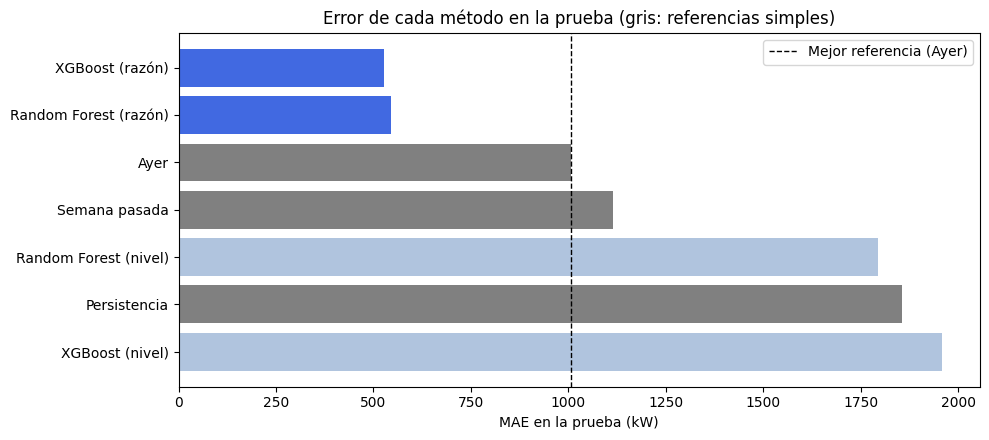

In [24]:
orden = df_results["MAE (kW)"].sort_values()
colores_barras = ["grey" if n in referencias else ("royalblue" if "razón" in n else "lightsteelblue") for n in orden.index]
plt.figure(figsize=(10, 4.5))
plt.barh(orden.index[::-1], orden.values[::-1], color=colores_barras[::-1])
plt.axvline(mae_mejor, color="black", ls="--", lw=1, label=f"Mejor referencia ({mejor_ref})")
plt.xlabel("MAE en la prueba (kW)")
plt.title("Error de cada método en la prueba (gris: referencias simples)")
plt.legend()
plt.tight_layout()
plt.show()

## **Diagnóstico**

### Real contra predicho

Una semana de la prueba, con el mejor modelo y la mejor referencia simple. Los valores se grafican en la hora que se
predice (t+6).

Mejor modelo en la prueba: XGBoost (razón)


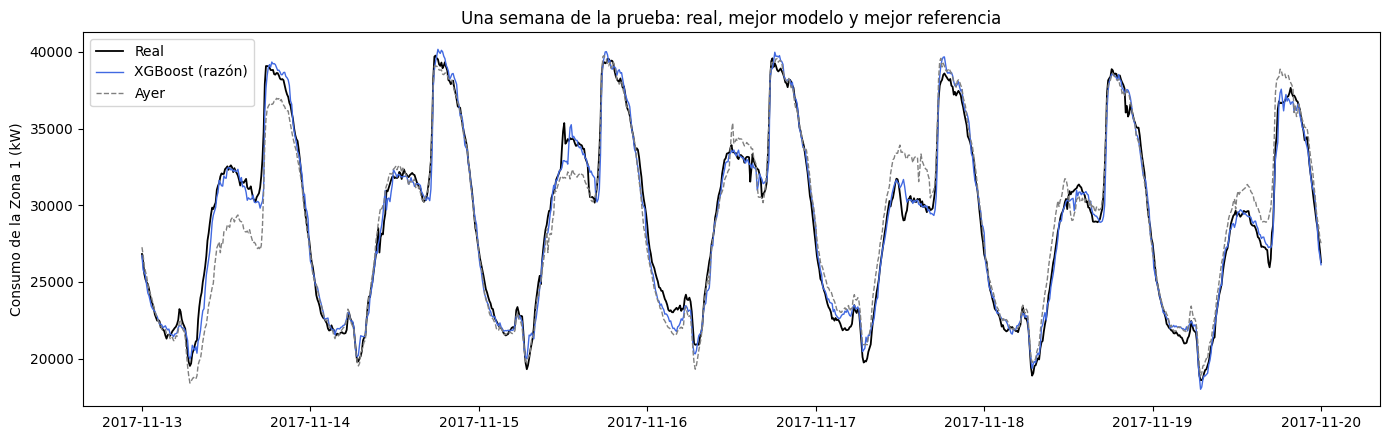

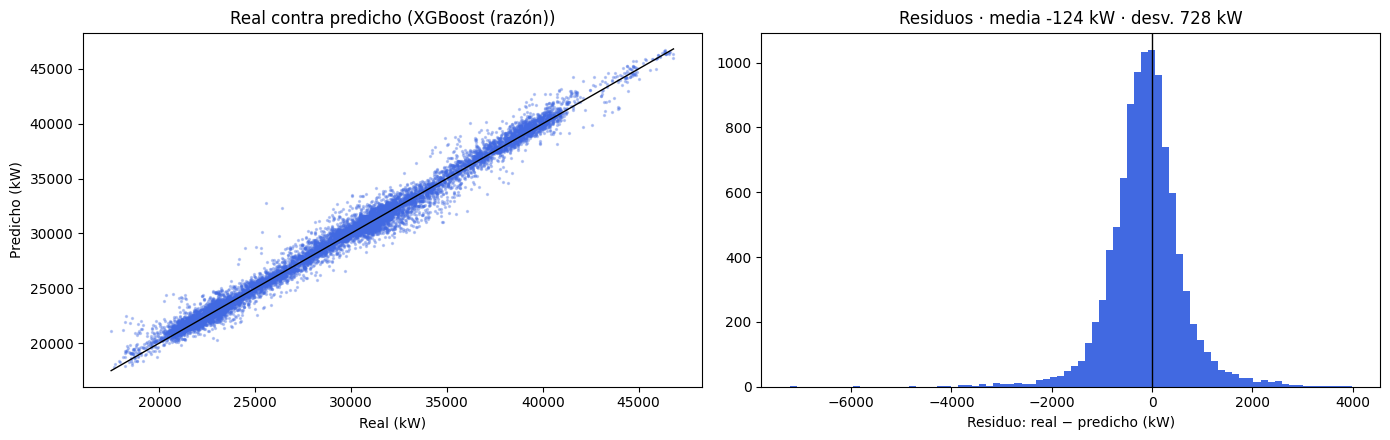

In [25]:
mejor_modelo = df_results.loc[list(predicciones), "MAE (kW)"].idxmin()
print("Mejor modelo en la prueba:", mejor_modelo)
objetivo = fechas_test + pd.Timedelta(minutes=10 * H)
semana = objetivo.between("2017-11-13", "2017-11-20").to_numpy()
plt.figure(figsize=(14, 4.5))
plt.plot(objetivo[semana], y_test[semana], color="black", lw=1.3, label="Real")
plt.plot(objetivo[semana], predicciones[mejor_modelo][semana], color="royalblue", lw=1, label=mejor_modelo)
plt.plot(objetivo[semana], referencias[mejor_ref][semana], color="grey", lw=1, ls="--", label=mejor_ref)
plt.ylabel("Consumo de la Zona 1 (kW)")
plt.title("Una semana de la prueba: real, mejor modelo y mejor referencia")
plt.legend()
plt.tight_layout()
plt.show()

residuo = y_test.to_numpy() - predicciones[mejor_modelo]
fig, (eje1, eje2) = plt.subplots(1, 2, figsize=(14, 4.5))
eje1.scatter(y_test, predicciones[mejor_modelo], s=2, alpha=0.3, color="royalblue")
limites = [y_test.min(), y_test.max()]
eje1.plot(limites, limites, color="black", lw=1)
eje1.set(xlabel="Real (kW)", ylabel="Predicho (kW)", title=f"Real contra predicho ({mejor_modelo})")
eje2.hist(residuo, bins=80, color="royalblue")
eje2.axvline(0, color="black", lw=1)
eje2.set(xlabel="Residuo: real − predicho (kW)", title=f"Residuos · media {residuo.mean():.0f} kW · desv. {residuo.std():.0f} kW")
plt.tight_layout()
plt.show()

### Error por hora y por semana

El error por hora muestra si el modelo falla en los picos (18 a 22 h). El error por semana muestra el efecto de la
**transferencia de carga del 25 de octubre**: ese día parte de la carga de la Zona 1 pasó a la Zona 2 (la Zona 1
bajó cerca de 12 %), así que las referencias de ayer y de la semana pasada quedan desfasadas unos días.

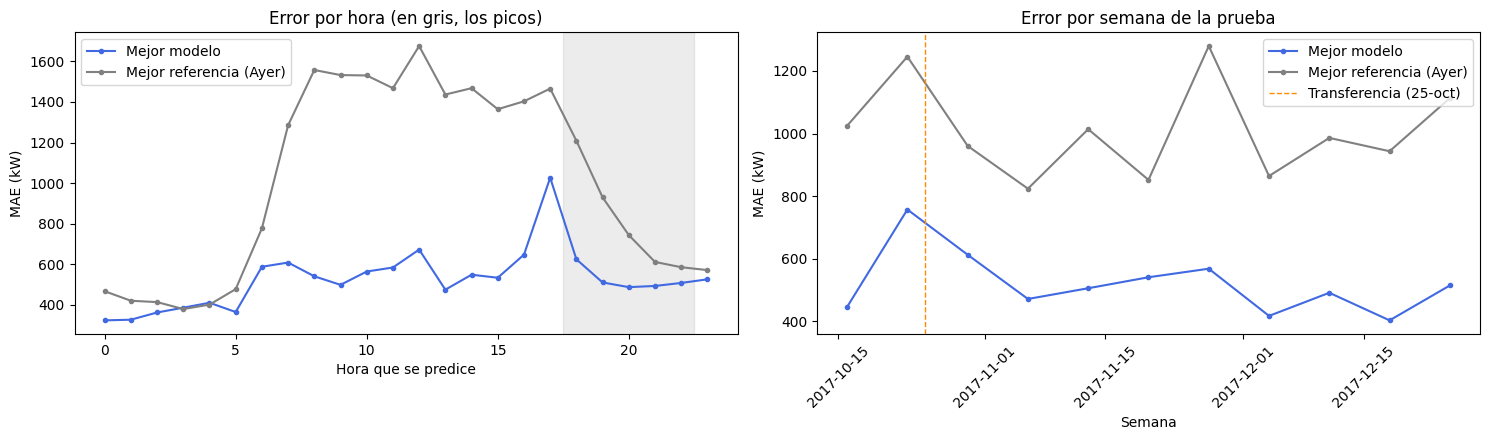

MAE en los picos (18 a 22 h): {'Mejor modelo': 525.0, 'Mejor referencia (Ayer)': 816.0}
MAE por semana (lunes de inicio):


,Mejor modelo,Mejor referencia (Ayer)
2017-10-16,447.0,1025.0
2017-10-23,757.0,1246.0
2017-10-30,613.0,961.0
2017-11-06,472.0,824.0
2017-11-13,506.0,1014.0
2017-11-20,541.0,852.0
2017-11-27,569.0,1279.0
2017-12-04,418.0,864.0
2017-12-11,492.0,986.0
2017-12-18,404.0,944.0


In [26]:
errores_abs = pd.DataFrame({"Mejor modelo": np.abs(y_test.to_numpy() - predicciones[mejor_modelo]),
                            f"Mejor referencia ({mejor_ref})": np.abs(y_test.to_numpy() - referencias[mejor_ref].to_numpy())})
fig, (eje1, eje2) = plt.subplots(1, 2, figsize=(15, 4.5))
errores_abs.groupby(objetivo.dt.hour.to_numpy()).mean().plot(ax=eje1, marker="o", ms=3, color=["royalblue", "grey"])
eje1.axvspan(17.5, 22.5, color="grey", alpha=0.15)
eje1.set(xlabel="Hora que se predice", ylabel="MAE (kW)", title="Error por hora (en gris, los picos)")
por_semana = errores_abs.groupby(objetivo.dt.to_period("W").dt.start_time.to_numpy()).mean()
for col, color in zip(por_semana.columns, ["royalblue", "grey"]):  # con matplotlib: fechas reales en el eje
    eje2.plot(por_semana.index, por_semana[col], marker="o", ms=3, color=color, label=col)
eje2.axvline(pd.Timestamp("2017-10-25"), color="darkorange", ls="--", lw=1, label="Transferencia (25-oct)")
eje2.tick_params(axis="x", labelrotation=45)
eje2.set(xlabel="Semana", ylabel="MAE (kW)", title="Error por semana de la prueba")
eje2.legend()
plt.tight_layout()
plt.show()
pico = objetivo.dt.hour.between(18, 22).to_numpy()
print("MAE en los picos (18 a 22 h):", errores_abs[pico].mean().round(0).to_dict())
print("MAE por semana (lunes de inicio):")
display(por_semana.round(0))

## **Importancia de Variables**

Cuánto aporta cada variable al XGBoost en razón (ganancia media de las divisiones que usan la variable).

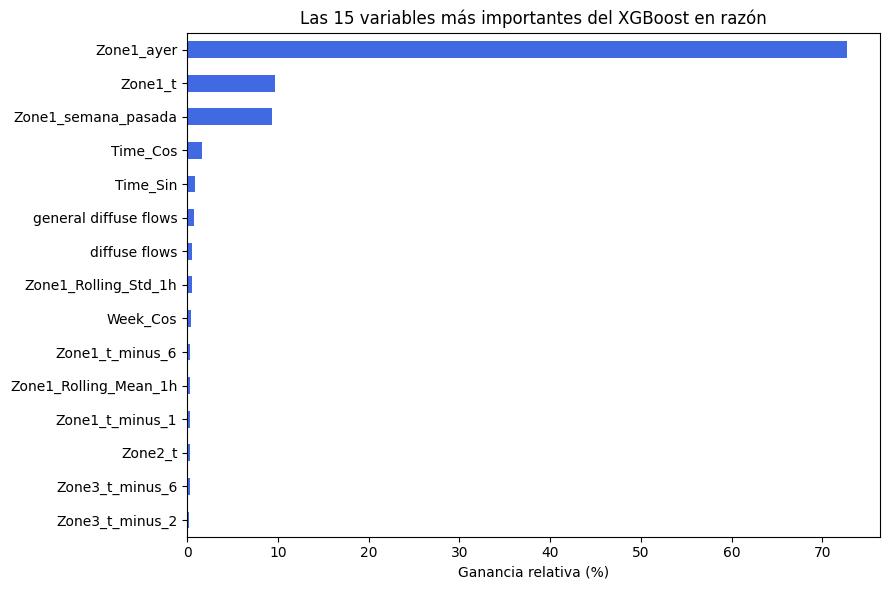

In [27]:
importancia = pd.Series(modelos["XGBoost (razón)"].get_booster().get_score(importance_type="gain")).sort_values()
importancia = 100 * importancia / importancia.sum()
plt.figure(figsize=(9, 6))
importancia.tail(15).plot.barh(color="royalblue")
plt.xlabel("Ganancia relativa (%)")
plt.title("Las 15 variables más importantes del XGBoost en razón")
plt.tight_layout()
plt.show()

# **Conclusiones y lecciones aprendidas**

## Resultados en la prueba (20 de octubre al 30 de diciembre de 2017)

1. **La mejor referencia simple es "ayer a la misma hora"**, con un MAE de 1,007 kW (MAPE 3.5 %). La persistencia,
   que era la vara de la versión anterior, queda en 1,857 kW: casi el doble.
2. **En nivel, los dos modelos pierden contra "ayer"**: Random Forest 1,795 kW y XGBoost 1,958 kW. Le ganan a la
   persistencia, pero no aportan valor frente a copiar el consumo del día anterior. Además son inestables: con una
   semana menos de entrenamiento y el hueco de una hora, el MAE del XGBoost en nivel pasó de 1,631 kW (versión
   anterior) a 1,958 kW.
3. **En razón, los dos le ganan a la mejor referencia por casi la mitad**: XGBoost 526 kW (MAPE 1.8 %, R² 0.99) y
   Random Forest 544 kW (MAPE 1.9 %). **El modelo elegido es XGBoost en razón**: tiene el menor error en las cuatro
   métricas y entrena en alrededor de un segundo en la GPU.
4. **En los picos (18 a 22 h)** el modelo se equivoca en promedio 525 kW, frente a 816 kW de "ayer". Su peor hora es
   la subida de las 17 h, cuando el consumo salta hacia el pico de la noche.
5. **La transferencia de carga del 25 de octubre** se nota: la semana que la contiene es la de mayor error del
   modelo (757 kW); la siguiente baja a 613 kW y desde noviembre se mantiene entre 400 y 570 kW, porque la media
   de 24 h ya refleja la nueva carga de la Zona 1. Aun en esa semana le gana a "ayer" (1,246 kW).
6. **El consumo de ayer a la hora de t+6** es la variable que más pesa en el XGBoost (cerca de 73 % de la ganancia),
   seguida por el consumo actual y el de la semana pasada (alrededor de 10 % cada uno). El clima casi no aporta a
   una hora.

## Lecciones aprendidas

- **La referencia define la conclusión.** Contra la persistencia, cualquier modelo parece bueno; contra "ayer", solo
  los que aprenden la forma del día. El criterio de éxito tiene que medirse contra la mejor referencia simple.
- **Con un solo año de datos, predecir el nivel obliga a extrapolar**, y los árboles no predicen valores que no vieron.
  Predecir la razón con la media de 24 h fue lo que más mejoró el resultado; cambiar de algoritmo movió mucho menos
  (526 frente a 544 kW).
- **La división cronológica con un hueco** evita que el objetivo del entrenamiento se filtre en la prueba.
- **CRISP-DM es iterativo:** la evaluación devolvió el trabajo a la preparación de los datos (nuevas variables y otro
  objetivo), que es donde estaba la mejora.